# StatsForecast's automatic models

StatsForecast's (Nixtla) `AutoARIMA`, `AutoETS`, `AutoTheta` and `AutoCES` models are available as optional base models: `sf_auto_arima`, `sf_auto_ets`, `sf_auto_theta` and `sf_auto_ces`. This notebook compares these models with the statsmodels equivalents and with baselines on the same origins, shows that the parameters stay frozen after fitting (a requirement of variant B) and reproduces the statistical-ANN hybrids of the replication project.

**Requirements:** the `nixtla-stats` extra (`pip install "autohybts[nixtla-stats]"`). StatsForecast requires `pandas<3`, so the extra installs pandas 2.x; in an environment with pandas 3, use a second virtual environment. Guide: `user_guide/nixtla`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd

import autohybts
from autohybts import AutoHybridExperiment
from autohybts.datasets import get_data
from autohybts.domain.fit_count import count_fits
from autohybts.residuals.generation import local_context

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)


def clean(ax, grid_axis="both"):
    """Recessive grid and axes; text in neutral ink."""
    ax.grid(axis=grid_axis, color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.tick_params(colors="#52514e")


import statsforecast  # noqa: E402

print(
    "AutoHybTS",
    autohybts.__version__,
    "| StatsForecast",
    statsforecast.__version__,
    "| pandas",
    pd.__version__,
)

AutoHybTS 0.0.1 | StatsForecast 2.1.1 | pandas 2.3.3


## 1. Data and protocol

Synthetic daily series (trend, weekly seasonality, AR(0.7) noise), `fh=14`, 3 origins on `V_search` and 3 on `V_select`, seed 42. The sealed test (last 14 days) is read only at the end.

In [2]:
y = get_data("synthetic_daily", n=500)
exp = AutoHybridExperiment(fh=14, fold=3, session_id=42).fit(y)
exp.splits

,layer,train_start,origin,first_target,last_target,n_train,horizon
fold_id,,,,,,,
search-0,search,2024-01-01,2025-02-05,2025-02-06,2025-02-19,402,14
search-1,search,2024-01-01,2025-02-19,2025-02-20,2025-03-05,416,14
search-2,search,2024-01-01,2025-03-05,2025-03-06,2025-03-19,430,14
select-0,select,2024-01-01,2025-03-19,2025-03-20,2025-04-02,444,14
select-1,select,2024-01-01,2025-04-02,2025-04-03,2025-04-16,458,14
select-2,select,2024-01-01,2025-04-16,2025-04-17,2025-04-30,472,14


## 2. Each model on the same origins

The four StatsForecast models with `season_length=7`, against the statsmodels models (`arima`, `exponential_smoothing` with weekly Holt-Winters) and `seasonal_naive`. Mean MASE per layer and evaluation seconds (all 6 origins).

In [3]:
candidates = {
    "seasonal_naive": {},
    "exponential_smoothing": {"season_length": 7},
    "arima": {},
    "sf_auto_ets": {"season_length": 7},
    "sf_auto_arima": {"season_length": 7},
    "sf_auto_theta": {"season_length": 7},
    "sf_auto_ces": {"season_length": 7},
}
rows = []
for name, params in candidates.items():
    started = time.perf_counter()
    frame = exp.create_model(name, **params).evaluation.to_frame()
    rows.append(
        {
            "model": name,
            "MASE V_search": frame.loc[frame["layer"] == "search", "MASE"].mean(),
            "MASE V_select": frame.loc[frame["layer"] == "select", "MASE"].mean(),
            "seconds": time.perf_counter() - started,
        }
    )
scores = pd.DataFrame(rows).set_index("model")
scores.round(3).sort_values("MASE V_select")

,MASE V_search,MASE V_select,seconds
model,,,
arima,0.916,0.877,47.166
exponential_smoothing,0.914,0.881,8.885
sf_auto_arima,0.874,0.888,162.075
sf_auto_ets,0.888,0.891,13.675
sf_auto_ces,0.914,0.912,0.382
sf_auto_theta,0.908,0.964,0.638
seasonal_naive,1.288,1.522,0.022


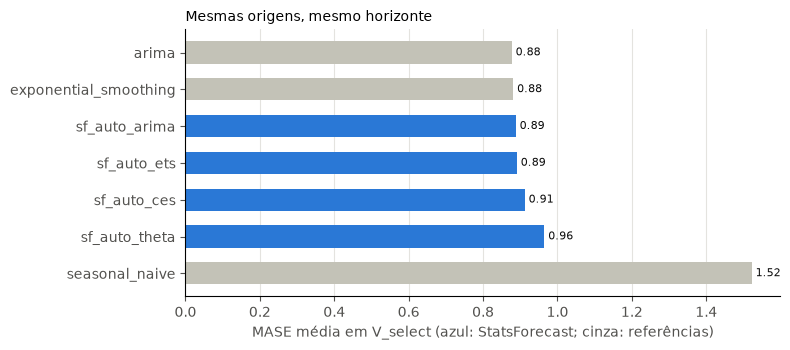

In [4]:
order = scores.sort_values("MASE V_select").index[::-1]
colors = ["#2a78d6" if name.startswith("sf_") else "#c3c2b7" for name in order]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(order, scores.loc[order, "MASE V_select"], color=colors, height=0.6)
for row, value in enumerate(scores.loc[order, "MASE V_select"]):
    ax.text(value, row, f" {value:.2f}", va="center", fontsize=8, color="#0b0b0b")
ax.set_xlabel("mean MASE on V_select (blue: StatsForecast; grey: references)", color="#52514e")
ax.set_title("Same origins, same horizon", loc="left", fontsize=10)
clean(ax, grid_axis="x")
fig.tight_layout()

## 3. Frozen parameters

In variant B and in the out-of-sample residuals, a fitted model forecasts from longer contexts without being refitted. The adapter uses StatsForecast's `forward`: on the training data itself it reproduces the fitted forecast; with 20 more observations, only the states change (no fit is counted), and the result differs from a full refit.

In [5]:
values = y.to_numpy()
rows = []
for name in ["sf_auto_ets", "sf_auto_arima"]:
    model = exp.registry_.make_base(name, {"season_length": 7}).fit(values[:400])
    with count_fits() as fits:
        frozen = model.predict(7, local_context(values, 420))
    refit = exp.registry_.make_base(name, {"season_length": 7}).fit(values[:420])
    rows.append(
        {
            "model": name,
            "fits while forecasting": fits.total,
            "frozen forecast (h=1)": frozen[0],
            "after refit (h=1)": refit.predict(7, local_context(values, 420))[0],
            "observed": values[420],
        }
    )
pd.DataFrame(rows).set_index("model").round(3)

,fits while forecasting,frozen forecast (h=1),after refit (h=1),observed
model,,,,
sf_auto_ets,0,64.702,64.738,64.164
sf_auto_arima,0,64.239,64.267,64.164


## 4. The statistical-ANN hybrids of the replication

The replication project uses AutoETS, AutoARIMA and AutoSARIMA with an MLP of 5 logistic neurons on the out-of-sample residuals. The same configurations become AutoHybTS specifications; `scale="minmax"` and `feature_order="lag"` reproduce the project's corrector (exact parity is tested in `tests/regression/test_legacy_parity.py`).

In [6]:
ann = {
    "scale": "minmax",
    "feature_order": "lag",
    "random_state": 42,
    "estimator_params": {
        "hidden_layer_sizes": [5],
        "activation": "logistic",
        "solver": "lbfgs",
        "max_iter": 2000,
        "alpha": 0.0001,
        "tol": 0.0001,
    },
}
bases = {
    "ETS-ANN": ("sf_auto_ets", {"season_length": 7, "model_params": {"model": "ZZZ"}}),
    "ARIMA-ANN": ("sf_auto_arima", {"season_length": 1, "model_params": {"seasonal": False}}),
    "SARIMA-ANN": ("sf_auto_arima", {"season_length": 7, "model_params": {"seasonal": True}}),
}
rows = []
for label, (base, params) in bases.items():
    alone = exp.create_model(base, **params).evaluation.to_frame()
    hybrid = exp.create_hybrid(base, "mlp", window=7, base_params=params, corrector_params=ann)
    frame = hybrid.evaluation.to_frame()
    rows.append(
        {
            "hybrid": label,
            "base MASE (V_select)": alone.loc[alone["layer"] == "select", "MASE"].mean(),
            "hybrid MASE (V_select)": frame.loc[frame["layer"] == "select", "MASE"].mean(),
            "variability": hybrid.evaluation.trials[0].diagnostics["correction_std_ratio"],
        }
    )
pd.DataFrame(rows).set_index("hybrid").round(3)

,base MASE (V_select),hybrid MASE (V_select),variability
hybrid,,,
ETS-ANN,0.891,0.882,0.303
ARIMA-ANN,1.284,1.317,0.293
SARIMA-ANN,0.888,0.875,0.280


## 5. Search with the StatsForecast models

Passed in `base_models`, they join the search like the others: the seasonal period comes from the experiment.

In [7]:
search = AutoHybridExperiment(
    fh=14,
    fold=3,
    session_id=42,
    budget="small",
    base_models=["seasonal_naive", "linear", "sf_auto_ets", "sf_auto_theta", "sf_auto_ces"],
    correctors=["linear", "mlp"],
    residual_windows=[14],
    alphas=[1.0],
).fit(y)
result = search.compare_models()
print(f"candidates: {result.search.trial_count}, fits: {result.search.fit_count}")
print("champion:", result.best.label)
result.decisions[
    [
        "family",
        "champion_before",
        "challenger",
        "accepted",
        "reason_codes",
        "median_gain",
        "win_rate",
    ]
]

candidates: 13, fits: 93
champion: sf_auto_ets(season_length=7)


,family,champion_before,challenger,accepted,reason_codes,median_gain,win_rate
0,linear,sf_auto_ets,linear,False,"(median_gain_below_threshold, win_rate_below_t...",-0.636219,0.333333
1,residual,sf_auto_ets,sf_auto_ets-linear,False,"(median_gain_below_threshold,)",0.009861,0.666667


## 6. External evaluation

A single reading of the sealed test, after freezing the choice.

In [8]:
final = search.finalize_model(result.best)
search.evaluate_external(final).metrics.round(3)

,MASE,MAE,RMSE,sMAPE
model,,,,
sf_auto_ets(season_length=7),0.68,1.064,1.529,0.016


## 7. Reading

In this run (500 days, `fh=14`, 3 origins per layer — `fold=3` set explicitly, to keep the notebook fast —, StatsForecast 2.1.1 with pandas 2.3):

* **StatsForecast's automatic models tie with the statsmodels ones.** On `V_select`: `arima` (statsmodels) 0.877, `exponential_smoothing` 0.881, `sf_auto_arima` 0.888, `sf_auto_ets` 0.891, `sf_auto_ces` 0.912 and `sf_auto_theta` 0.964, all far ahead of `seasonal_naive` (1.52). Differences of 1% with 3 origins do not separate the models.
* **Cost.** `sf_auto_arima` took 162 s over the 6 origins (a seasonal order search at each one), against 47 s for statsmodels' `arima`; `sf_auto_ets` and `exponential_smoothing` took 9–14 s; `sf_auto_ces` and `sf_auto_theta`, less than 1 s. The times were measured with other runs in parallel; use them to compare the models with each other.
* **Frozen parameters.** Forecasting 20 days after training, no fit is made; the frozen forecast differs from a full refit's by ~0.03 (ETS 64.70 against 64.74; observed 64.16): the model takes in the new observations through its states, as variant B requires.
* **Statistical-ANN hybrids of the replication.** The residual MLP slightly improved the seasonal bases (ETS 0.891 → 0.882; SARIMA 0.888 → 0.875, ~1–1.5%) and worsened the non-seasonal one (ARIMA 1.284 → 1.317): without the seasonal term, the weekly error is left to a window-7 corrector that does not recover it.
* **In the search** (13 candidates, 93 fits), the champion was `sf_auto_ets`. The `sf_auto_ets-linear` hybrid won 2 out of 3 units, but with a median gain of 0.99%, below the 5% minimum of the default rule (ADR-0008): rejected. On the sealed test, the champion had MASE 0.68.

StatsForecast's models widen the statistical bases without changing the protocol; on this series, they did not beat the equivalents already present. Use them when the automatic order and component search is worth the cost, always compared against the references on the same origins.